🛒 E-Commerce Sales Performance
Company: SwiftCart Retail Role: Sales Operations Analyst

🏢 Scenario
SwiftCart Retail is looking to optimize its inventory for the next quarter. You have been assigned to identify which product categories are “cash cows” and which ones are underperforming based on sales performance and customer feedback.

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))
display(df)

Saving ecommerce_sales_dataset.csv to ecommerce_sales_dataset (1).csv


,Order_ID,Product_Category,Price,Quantity,Customer_Rating
0,1001,Books,1894,4,3.8
1,1002,Electronics,2210,1,4.6
2,1003,Clothing,897,2,4.2
3,1004,Clothing,3890,1,2.8
4,1005,Electronics,3529,3,3.6
5,1006,Home,2228,2,4.7
6,1007,Home,697,3,4.8
7,1008,Home,2349,4,4.8
8,1009,Home,3522,4,2.5
9,1010,Home,3080,5,4.4



1️⃣ Calculate Revenue
Create a new column called Total_Sales using the formula:
Total_Sales = Price × Quantity
This will represent the total revenue generated per product.

In [ ]:
import pandas as pd

df["Total_Sales"] = df["Price"] * df["Quantity"]

display(df)
print("Total Revenue:", df["Total_Sales"].sum())

,Order_ID,Product_Category,Price,Quantity,Customer_Rating,Total_Sales
0,1001,Books,1894,4,3.8,7576
1,1002,Electronics,2210,1,4.6,2210
2,1003,Clothing,897,2,4.2,1794
3,1004,Clothing,3890,1,2.8,3890
4,1005,Electronics,3529,3,3.6,10587
5,1006,Home,2228,2,4.7,4456
6,1007,Home,697,3,4.8,2091
7,1008,Home,2349,4,4.8,9396
8,1009,Home,3522,4,2.5,14088
9,1010,Home,3080,5,4.4,15400


Total Revenue: 143323


2️⃣ Identify Top Performers
Group the data by Category.
Calculate total sales per category.
Determine which category has the highest total sales.

In [ ]:
df["Total_Sales"] = df["Price"] * df["Quantity"]
sales = df.groupby("Product_Category")["Total_Sales"].sum()
display(sales)
print("Top Category:", sales.idxmax())
print("Total Sales:", sales.max())

,Total_Sales
Product_Category,
Books,7576
Clothing,24963
Electronics,38910
Home,71874


Top Category: Home
Total Sales: 71874


3️⃣ Customer Satisfaction Analysis
Compute the average product rating across all products.
Briefly interpret what this means for overall customer satisfaction.

In [ ]:
total = 0
count = 0
for rating in df["Customer_Rating"].dropna():
    total += rating
    count += 1
    print("Rating:", rating, "| Running Total:", total)

average = total / count

print("\nTotal Rating:", total)
print("Number of Ratings:", count)
print("Average Product Rating:", round(average, 2))

Rating: 3.8 | Running Total: 3.8
Rating: 4.6 | Running Total: 8.399999999999999
Rating: 4.2 | Running Total: 12.599999999999998
Rating: 2.8 | Running Total: 15.399999999999999
Rating: 3.6 | Running Total: 19.0
Rating: 4.7 | Running Total: 23.7
Rating: 4.8 | Running Total: 28.5
Rating: 4.8 | Running Total: 33.3
Rating: 2.5 | Running Total: 35.8
Rating: 4.4 | Running Total: 40.199999999999996
Rating: 3.0 | Running Total: 43.199999999999996
Rating: 4.8 | Running Total: 47.99999999999999
Rating: 4.2 | Running Total: 52.199999999999996
Rating: 2.9 | Running Total: 55.099999999999994
Rating: 2.6 | Running Total: 57.699999999999996
Rating: 5.0 | Running Total: 62.699999999999996
Rating: 3.1 | Running Total: 65.8
Rating: 2.9 | Running Total: 68.7
Rating: 3.4 | Running Total: 72.10000000000001
Rating: 5.0 | Running Total: 77.10000000000001

Total Rating: 77.10000000000001
Number of Ratings: 20
Average Product Rating: 3.86


4️⃣ Premium Product Filtering
Filter and list all products where:
Rating > 4
These represent high-performing, highly rated products.

In [ ]:
high_rated = df[df["Customer_Rating"] > 4]
display(high_rated)
print("Total Products:", len(high_rated))

,Order_ID,Product_Category,Price,Quantity,Customer_Rating
1,1002,Electronics,2210,1,4.6
2,1003,Clothing,897,2,4.2
5,1006,Home,2228,2,4.7
6,1007,Home,697,3,4.8
7,1008,Home,2349,4,4.8
9,1010,Home,3080,5,4.4
11,1012,Electronics,1679,1,4.8
12,1013,Home,2130,2,4.2
15,1016,Home,2703,4,5.0
19,1020,Clothing,2759,5,5.0


Total Products: 10


5️⃣ Visualization – Sales Performance
Create a Bar Chart showing:
Category vs. Total Sales
Include:

Chart title
Axis labels
Clear formatting for readability

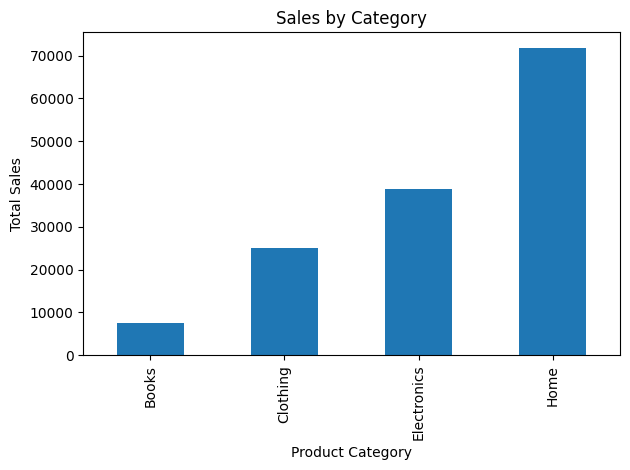

In [ ]:
import matplotlib.pyplot as plt
df["Total_Sales"] = df["Price"] * df["Quantity"]
sales = df.groupby("Product_Category")["Total_Sales"].sum()
sales.plot(kind="bar", title="Sales by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

6️⃣ Pricing Analysis
Create a Histogram of product prices.

Analyze:

Most common price ranges
Price distribution trends

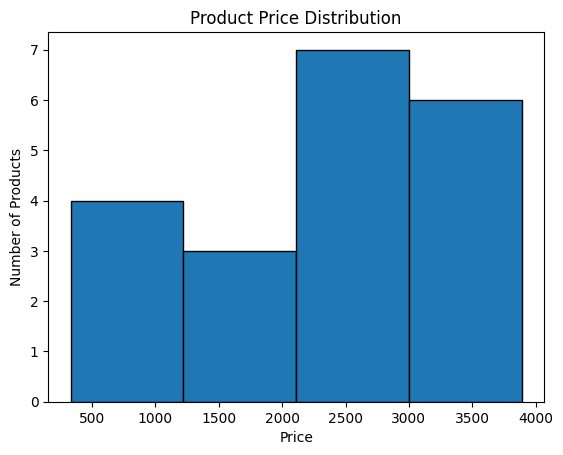

In [ ]:
plt.hist(df["Price"], bins=4, edgecolor="black")
plt.title("Product Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()